# 04b. Modèle du décrochage au primaire

Sentinelle Scolaire, défi 1.

La cible est le **taux d'abandon du primaire** de la province entre l'année t et t+1, pour l'ensemble des élèves et par sexe. Seules les cibles observées hors rupture de scolarisation servent à apprendre et à évaluer (notebook 04a).

Le modèle a trois briques :

1. **Prévision** du taux d'abandon à 1, 2 et 3 ans, avec un intervalle à 80 % calibré. Huit modèles sont comparés dans le temps ; le niveau habituel de la province est le modèle à battre : un autre n'est retenu que s'il réduit l'erreur d'au moins 3 % et gagne au moins deux plis sur trois.

**Normalisation de la cible.** Les modèles apprennent sur z = logit(taux / 100) ; prévisions et intervalles sont dénormalisés (taux = 100 / (1 + e^(−z))), donc toujours entre 0 et 100 %. Les taux apparents négatifs (arrivées nettes d'élèves, ramenés à zéro par la DGESS) prennent la valeur plancher de 0,5 %.

**Optimisation sans fuite d'information.** Dans chaque pli, les variables sont classées par importance par permutation (mesurée sur la dernière année de l'apprentissage) et chaque modèle garde ses k premières ; k, les pénalités, les paramètres de LightGBM et le rétrécissement vers la région sont choisis sur les plis de sélection. Le modèle final garde les variables retenues dans au moins la moitié des plis.
2. **Explication** : pourquoi une province a un niveau habituel d'abandon élevé (contribution de chaque variable, en points de taux).
3. **Alerte de rupture** : risque que la scolarisation s'effondre (variation des effectifs de plus de 30 %).

**Validation dans le temps.** Pour une cible de l'année Y, l'apprentissage n'utilise que des cibles connues à la date des variables. Trois plis servent aux choix ; le test final (2024-2025 pour l'ensemble, 2023-2024 par sexe) n'est utilisé qu'une fois.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentinelle.analyse import executer_exploration, executer_modelisation

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})
SOURCE = "Source : annuaires DGESS, base apurée du défi 1. Calculs des auteurs."
COULEURS = {"reference_annee_precedente": "#bdbcb6", "reference_niveau_habituel": "#1f3a5f",
            "reference_niveau_retreci": "#6c8fb3",
            "elastic_net": "#2e9e55", "ridge_effet_province": "#8a8984", "lightgbm": "#e8935a",
            "moyenne_elastic_lightgbm": "#b5446e"}

In [2]:
executer_exploration()
tables = executer_modelisation()

## 1. Brique 1 : quel modèle prévoit le mieux ?

Erreur absolue moyenne (points de taux), corrélation de rang entre taux prévus et observés, et part des provinces du quintile le plus à risque effectivement retrouvées. Les modèles appris prédisent l'écart au niveau habituel de la province, diminué du choc commun à toutes les provinces l'année de la cible (une crise nationale n'est prévisible par aucune variable provinciale).

In [3]:
s = tables["synthese_modeles_ensemble"]
s[s["horizon"] == 1].pivot_table(index="modele", columns="role",
                                 values=["erreur_absolue_moyenne", "correlation_rang", "rappel_quintile_le_plus_a_risque"])

correlation_rang            erreur_absolue_moyenne            rappel_quintile_le_plus_a_risque           
role                              sélection test final              sélection test final                        sélection test final
modele                                                                                                                              
elastic_net                           0.539      0.557                  6.289      3.419                            0.548      0.750
lightgbm                              0.571      0.550                  6.185      4.348                            0.500      0.750
lightgbm_elimination                  0.552      0.478                  6.433      5.099                            0.548      0.750
moyenne_elastic_lightgbm              0.562      0.537                  6.181      3.758                            0.500      0.750
reference_annee_precedente            0.340      0.365                  7.767      4.442                            0.506      0.625
reference_niveau_habituel             0.541      0.557                  6.323      3.406                            0.548      0.750
reference_niveau_retreci              0.518      0.617                  6.271      3.614                            0.464      0.625
ridge_effet_province                  0.462      0.526                  7.000      3.427                            0.458      0.750

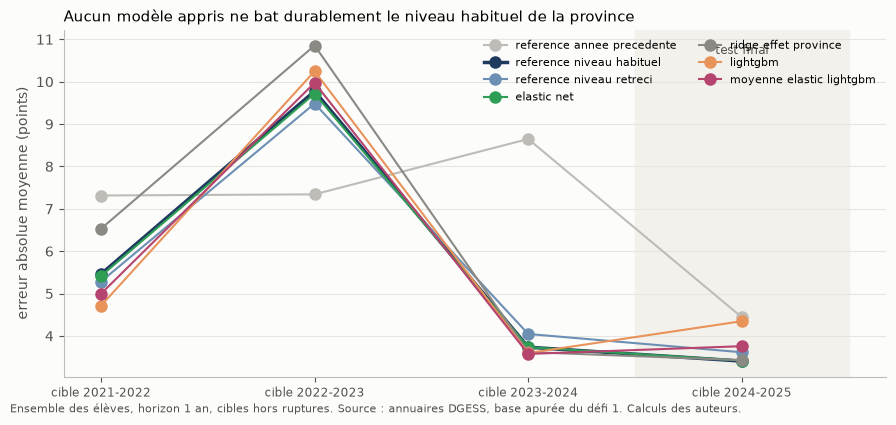

In [4]:
e = tables["evaluation_plis_ensemble"]
e1 = e[e["horizon"] == 1]
fig, ax = plt.subplots(figsize=(9, 4.2))
annees = sorted(e1["annee_cible"].unique())
for m, couleur in COULEURS.items():
    serie = e1[e1["modele"] == m].set_index("annee_cible")["erreur_absolue_moyenne"].reindex(annees)
    ax.plot(range(len(annees)), serie.values, marker="o", ms=8, lw=2.5 if m == "reference_niveau_habituel" else 1.5,
            color=couleur, label=m.replace("_", " "))
ax.axvspan(len(annees) - 1.5, len(annees) - 0.5, color="#f2f1ec", zorder=0)
ax.text(len(annees) - 1, ax.get_ylim()[1] * 0.97, "test final", ha="center", va="top", fontsize=8.5, color="#52514e")
ax.set_xticks(range(len(annees)), [f"cible {a}" for a in annees], fontsize=8.5)
ax.set_ylabel("erreur absolue moyenne (points)")
ax.grid(axis="y", color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax.set_title("Aucun modèle appris ne bat durablement le niveau habituel de la province", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Ensemble des élèves, horizon 1 an, cibles hors ruptures. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

**Lecture.** Même optimisés (normalisation logit, sélection des variables dans chaque pli, réglages), les modèles appris gagnent un peu les années de crise et perdent les années calmes ; aucun ne réduit l'erreur d'au moins 3 % de façon régulière par rapport au niveau habituel de la province (moyenne de ses taux passés hors ruptures). Les variables provinciales ne prévoient pas les variations d'une année sur l'autre, qui sont surtout des chocs communs : la prévision retenue est donc le niveau habituel. Le même constat vaut par sexe :

In [5]:
s = tables["synthese_modeles_sexe"]
s[s["horizon"] == 1].pivot_table(index="modele", columns="role", values=["erreur_absolue_moyenne", "correlation_rang"])

correlation_rang            erreur_absolue_moyenne           
role                              sélection test final              sélection test final
modele                                                                                  
elastic_net                           0.549      0.660                  6.321      3.829
lightgbm                              0.511      0.639                  6.488      4.126
lightgbm_elimination                  0.528      0.694                  6.321      3.396
moyenne_elastic_lightgbm              0.531      0.656                  6.365      3.891
reference_annee_precedente            0.328      0.484                  7.112      8.725
reference_niveau_habituel             0.549      0.660                  6.340      3.832
reference_niveau_retreci              0.512      0.523                  6.195      4.249
ridge_effet_province                  0.521      0.414                  7.274      4.867

In [6]:
pd.concat({"ensemble": tables["reglages_ensemble"], "par sexe": tables["reglages_sexe"]})

,,kappa,alpha_elastic,k_elastic,alpha_ridge,k_ridge,lightgbm,k_lightgbm,modele_retenu
ensemble,0,4.0,0.3,None,1000.0,5,0,15,reference_niveau_habituel
par sexe,0,8.0,0.3,5,1000.0,5,2,None,reference_niveau_habituel


Variables retenues par LightGBM dans les plis (horizon 1 an) : part des plis où chacune figure parmi les k premières.

In [7]:
v = tables["variables_retenues_ensemble"]
v[(v["horizon"] == 1) & (v["modele"] == "lightgbm")].head(15)

,modele,variable,part_des_plis,horizon
52,lightgbm,part_etab_post_primaire_secondaire_publics_electricite_region,1.00,1
53,lightgbm,part_ecoles_primaires_cycle_incomplet,1.00,1
54,lightgbm,abandons_primaire_orpaillage_pour_1000_region,0.75,1
55,lightgbm,part_cp1,0.75,1
56,lightgbm,evolution_eleves_primaire,0.50,1
57,lightgbm,abandon_primaire_precedent,0.50,1
58,lightgbm,moyenne_passee_abandon,0.50,1
59,lightgbm,part_enseignants_primaire_debutants,0.50,1
60,lightgbm,part_ecoles_primaires_electricite,0.50,1
61,lightgbm,deficit_places_pour_100_eleves_primaire,0.50,1


### Élimination récursive guidée par SHAP

Dans chaque pli, LightGBM est appris sur les variables restantes, les 10 % les moins importantes (contribution SHAP absolue moyenne) sont retirées, et l'erreur est mesurée sur la dernière année de l'apprentissage. Le nombre de variables retenu est le plus petit dont l'erreur reste à moins de 1 % de la meilleure ; le pli de test mesure ensuite le modèle ainsi réduit (modèle `lightgbm_elimination`).

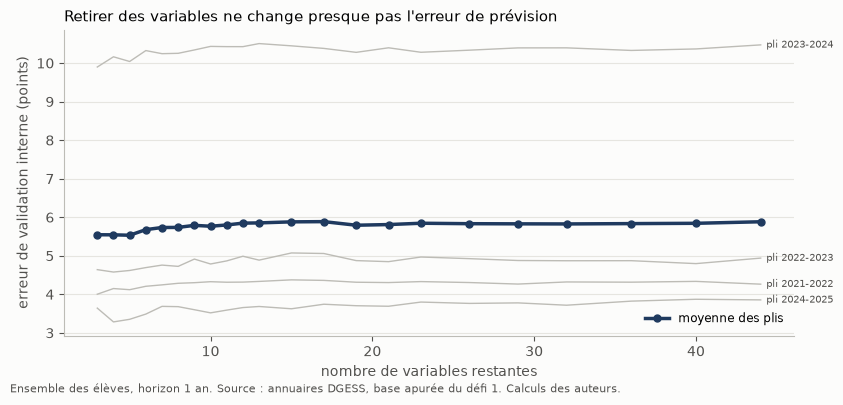

In [8]:
c = tables["courbe_elimination_prevision_ensemble"]
c = c[c["horizon"] == 1]
large = c.pivot_table(index="nombre_de_variables", columns="annee_cible", values="erreur_validation_interne")
fig, ax = plt.subplots(figsize=(8.5, 4))
for annee in large.columns:
    ax.plot(large.index, large[annee], color="#bdbcb6", lw=1)
    ax.annotate(f"pli {annee}", (large.index[-1], large[annee].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", fontsize=7.5, color="#52514e", va="center")
moyenne = large.mean(axis=1)
ax.plot(moyenne.index, moyenne.values, color="#1f3a5f", lw=2.5, marker="o", ms=5, label="moyenne des plis")
ax.set_xlabel("nombre de variables restantes")
ax.set_ylabel("erreur de validation interne (points)")
ax.grid(axis="y", color="#e6e5e0"); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Retirer des variables ne change presque pas l'erreur de prévision", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Ensemble des élèves, horizon 1 an. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

In [9]:
e = tables["evaluation_plis_ensemble"]
e[e["horizon"] == 1].pivot_table(index="modele", columns="annee_cible", values="erreur_absolue_moyenne").round(2)

annee_cible,2021-2022,2022-2023,2023-2024,2024-2025
modele,,,,
elastic_net,5.42,9.72,3.73,3.42
lightgbm,4.71,10.25,3.60,4.35
lightgbm_elimination,6.28,9.38,3.64,5.10
moyenne_elastic_lightgbm,4.99,9.97,3.57,3.76
reference_annee_precedente,7.31,7.34,8.65,4.44
reference_niveau_habituel,5.46,9.78,3.73,3.41
reference_niveau_retreci,5.28,9.48,4.05,3.61
ridge_effet_province,6.53,10.85,3.62,3.43


In [10]:
e = tables["evaluation_plis_sexe"]
e[e["horizon"] == 1].pivot_table(index="modele", columns="annee_cible", values="erreur_absolue_moyenne").round(2)

annee_cible,2020-2021,2021-2022,2022-2023,2023-2024
modele,,,,
elastic_net,3.86,5.36,9.74,3.83
lightgbm,4.28,4.82,10.37,4.13
lightgbm_elimination,4.13,4.78,10.06,3.40
moyenne_elastic_lightgbm,4.07,5.04,9.98,3.89
reference_annee_precedente,7.66,6.29,7.39,8.72
reference_niveau_habituel,3.84,5.41,9.78,3.83
reference_niveau_retreci,3.94,5.24,9.41,4.25
ridge_effet_province,3.92,5.87,12.04,4.87


## 2. L'intervalle à 80 %

La marge est calibrée sur l'échelle logit à partir des erreurs hors échantillon des plis (prédiction conforme), puis dénormalisée : l'intervalle est asymétrique, plus étroit vers 0, et ne sort jamais de [0 ; 100]. La couverture est mesurée sur le test final, jamais utilisé avant ; elle doit être proche de 80 % ou au-dessus. L'intervalle reste large parce que les plis comprennent les années de crise 2021-2023.

In [11]:
pd.concat({"ensemble": tables["intervalle_ensemble"], "par sexe": tables["intervalle_sexe"]})

horizon                     modele  marge_conforme_logit  couverture_test_final  largeur_moyenne_points  lignes
ensemble 0        1  reference_niveau_habituel                 0.875                  0.850                  17.203      40
         1        2  reference_niveau_habituel                 1.005                  0.875                  20.134      40
         2        3  reference_niveau_habituel                 0.937                  0.850                  17.127      40
par sexe 0        1  reference_niveau_habituel                 1.092                  0.906                  20.142      64
         1        2  reference_niveau_habituel                 1.209                  0.938                  20.968      64
         2        3  reference_niveau_habituel                 0.906                  0.812                  14.260      64

## 3. Les prévisions 2025-2026

Classe de risque : *élevé* au-dessus du 80e centile des taux observés, *moyen* au-dessus de la médiane.

In [12]:
tables["seuils_classes_ensemble"]

,classe,taux_abandon_prevu
0,moyen à partir de (médiane),8.43
1,élevé à partir de (80e centile),14.16


In [13]:
tb = tables["tableau_de_bord_ensemble"]
tb[["province_nom", "region_nom", "taux_abandon_annee_des_variables", "taux_abandon_prevu", "borne_basse_80",
    "borne_haute_80", "classe_de_risque", "risque_de_rupture", "province_scindee"]].head(20)

,province_nom,region_nom,taux_abandon_annee_des_variables,taux_abandon_prevu,borne_basse_80,borne_haute_80,classe_de_risque,risque_de_rupture,province_scindee
0,Loroum,Yaadga,34.350,25.43,13.27,43.17,élevé,élevé,False
1,Karo-Peli,Soum,18.680,24.89,12.95,42.47,élevé,élevé,True
2,Djelgodji,Soum,18.680,24.39,12.65,41.82,élevé,élevé,True
3,Seno,Liptako,18.310,24.24,12.56,41.62,élevé,élevé,False
4,Yagha,Liptako,19.370,23.69,12.23,40.88,élevé,élevé,False
5,Oudalan,Liptako,18.680,18.56,9.28,33.68,élevé,élevé,False
6,Dyamongou,Tapoa,9.745,17.72,8.81,32.42,élevé,élevé,True
7,Gobnangou,Tapoa,9.745,17.72,8.81,32.42,élevé,élevé,True
8,Kossin,Sourou,-1.370,16.25,8.01,30.18,élevé,faible,False
9,Namentenga,Koulse,17.180,15.57,7.64,29.12,élevé,moyen,False


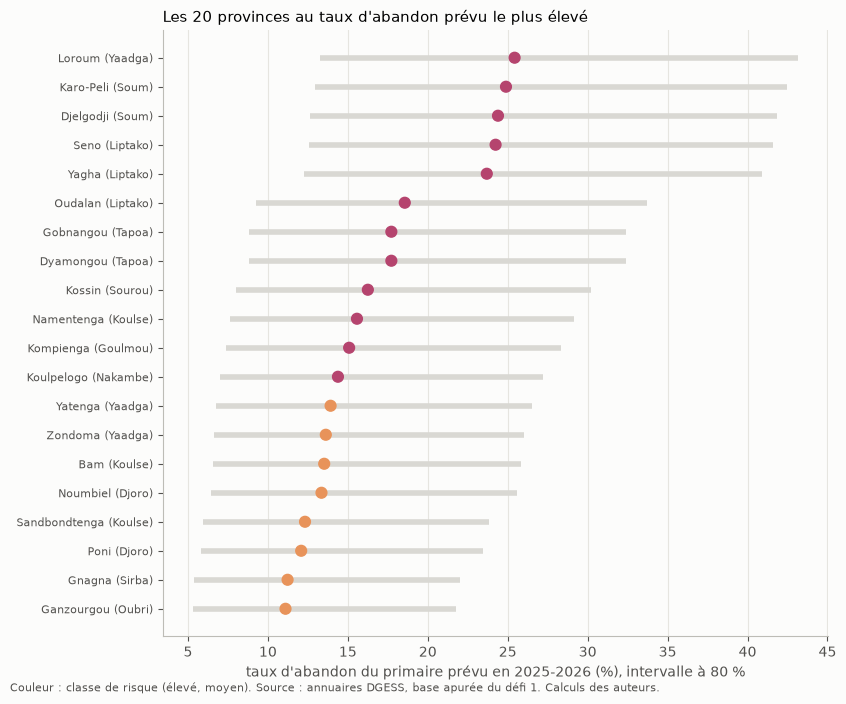

In [14]:
t = tb.sort_values("taux_abandon_prevu").tail(20)
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(t))
couleur = t["classe_de_risque"].map({"élevé": "#b5446e", "moyen": "#e8935a", "faible": "#8a8984"})
ax.hlines(y, t["borne_basse_80"].clip(lower=0), t["borne_haute_80"], color="#d9d8d3", lw=4)
ax.scatter(t["taux_abandon_prevu"], y, color=couleur, s=60, zorder=3)
ax.set_yticks(y, t["province_nom"] + " (" + t["region_nom"] + ")", fontsize=8)
ax.set_xlabel("taux d'abandon du primaire prévu en 2025-2026 (%), intervalle à 80 %")
ax.grid(axis="x", color="#e6e5e0")
ax.set_title("Les 20 provinces au taux d'abandon prévu le plus élevé", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Couleur : classe de risque (élevé, moyen). " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 4. Brique 2 : pourquoi ces provinces ?

Le niveau habituel de chaque province est expliqué par ses variables moyennes (sans les variables de persistance). La qualité est mesurée en prédisant des provinces que le modèle n'a pas vues ; le modèle (LightGBM ou elastic net) et le nombre k de variables sont choisis sur cette mesure, le classement des variables étant refait dans chaque pli.

In [15]:
pd.concat({"ensemble": tables["explication_validation_ensemble"], "par sexe": tables["explication_validation_sexe"]})

modele   k  unites  r2_provinces_non_vues  correlation_rang_provinces_non_vues  erreur_absolue_moyenne  retenu
ensemble 0              lightgbm   5      43                 0.4920                                0.807                  2.2930   False
         1              lightgbm   8      43                 0.4730                                0.743                  2.4980   False
         2              lightgbm  12      43                 0.4570                                0.734                  2.5840   False
         3              lightgbm  40      43                 0.4800                                0.740                  2.3130   False
         4           elastic_net   5      43                 0.6370                                0.804                  2.1600    True
         5           elastic_net   8      43                 0.5660                                0.783                  2.4600   False
         6           elastic_net  12      43                 0.4940                                0.705                  2.4740   False
         7           elastic_net  40      43                 0.3190                                0.745                  2.6510   False
         8  lightgbm_elimination   8      43                 0.5224                                  NaN                  2.4994   False
par sexe 0              lightgbm   5      86                 0.2070                                0.636                  3.4800   False
         1              lightgbm   8      86                 0.2760                                0.717                  3.2600   False
         2              lightgbm  12      86                 0.4010                                0.764                  3.0510   False
         3              lightgbm  41      86                 0.4320                                0.759                  2.9060   False
         4           elastic_net   5      86                 0.4220                                0.716                  3.0170   False
         5           elastic_net   8      86                 0.4730                                0.748                  2.8950    True
         6           elastic_net  12      86                -0.7300                                0.748                  3.6250   False
         7           elastic_net  41      86                 0.3070                                0.727                  3.0450   False
         8  lightgbm_elimination  20      86                 0.4481                                  NaN                  2.9679   False

Courbe d'élimination récursive (LightGBM guidé par SHAP) pour l'explication : part de variance expliquée des provinces non vues selon le nombre de variables, comparée au meilleur elastic net.

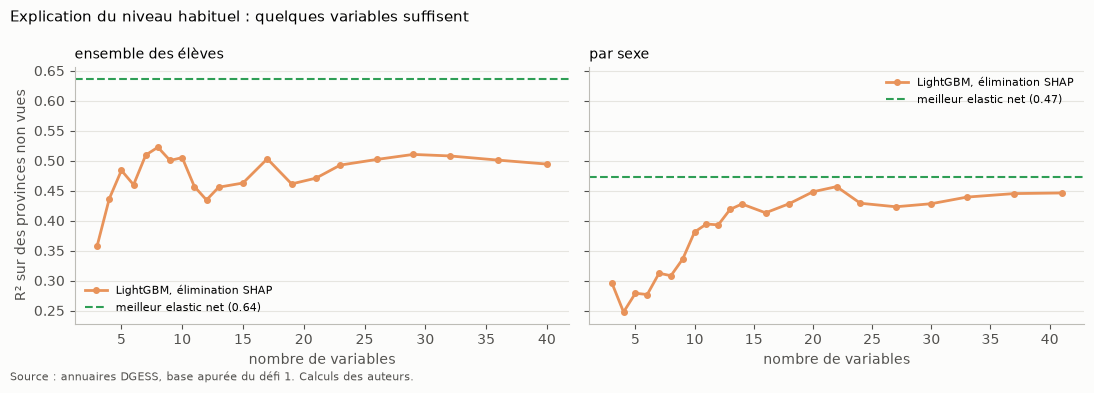

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, nom, titre in zip(axes, ["ensemble", "sexe"], ["ensemble des élèves", "par sexe"]):
    c = tables[f"explication_courbe_elimination_{nom}"]
    v = tables[f"explication_validation_{nom}"]
    ax.plot(c["nombre_de_variables"], c["r2_provinces_non_vues"], color="#e8935a", lw=2, marker="o", ms=4,
            label="LightGBM, élimination SHAP")
    meilleur = v[v["modele"] == "elastic_net"]["r2_provinces_non_vues"].max()
    ax.axhline(meilleur, color="#2e9e55", lw=1.5, ls="--", label=f"meilleur elastic net ({meilleur:.2f})")
    ax.set_xlabel("nombre de variables"); ax.set_title(titre, loc="left", fontsize=10)
    ax.grid(axis="y", color="#e6e5e0"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("R² sur des provinces non vues")
fig.suptitle("Explication du niveau habituel : quelques variables suffisent", x=0.01, ha="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

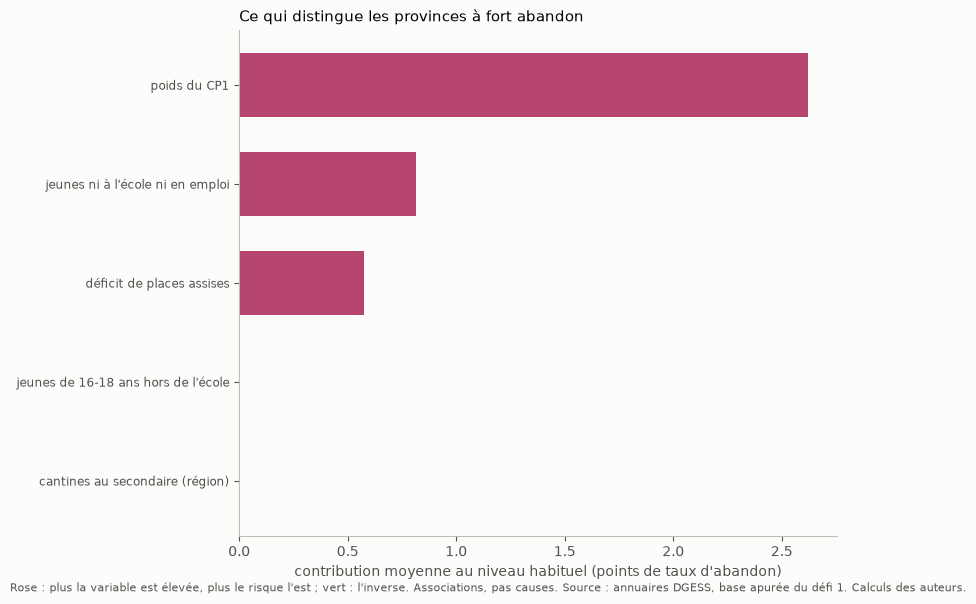

In [17]:
imp = tables["explication_importance_ensemble"].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
couleur = imp["sens"].map(lambda s: "#b5446e" if "plus le risque est élevé" in s else
                          ("#2e9e55" if "plus le risque est faible" in s else "#8a8984"))
ax.barh(imp["libelle"], imp["contribution_absolue_moyenne_points"], color=couleur, height=0.65)
ax.set_xlabel("contribution moyenne au niveau habituel (points de taux d'abandon)")
ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Ce qui distingue les provinces à fort abandon", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Rose : plus la variable est élevée, plus le risque l'est ; vert : l'inverse. "
         "Associations, pas causes. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

In [18]:
tables["explication_importance_ensemble"].head(15)

,variable,libelle,contribution_absolue_moyenne_points,sens
0,part_cp1,poids du CP1,2.621,"plus elle est élevée, plus le risque est élevé"
1,ni_ecole_ni_emploi_15_24_province,jeunes ni à l'école ni en emploi,0.816,"plus elle est élevée, plus le risque est élevé"
2,deficit_places_pour_100_eleves_primaire,déficit de places assises,0.576,"plus elle est élevée, plus le risque est élevé"
3,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,0.000,lien non monotone
4,part_etab_post_primaire_secondaire_publics_cantine_region,cantines au secondaire (région),0.000,lien non monotone


Effet de chaque variable retenue, dénormalisé : en points de taux d'abandon pour un point de pourcentage (parts) ou une unité de la variable.

In [19]:
tables["explication_effets_lineaires_ensemble"]

,variable,libelle,effet_pour_un_ecart_type_points,ecart_type_de_la_variable,unite,effet_par_unite_points
0,part_cp1,poids du CP1,3.220,0.0331,point de pourcentage,0.9717
1,ni_ecole_ni_emploi_15_24_province,jeunes ni à l'école ni en emploi,0.958,12.2366,unité de la variable,0.0783
2,deficit_places_pour_100_eleves_primaire,déficit de places assises,0.701,4.4759,unité de la variable,0.1565


In [20]:
tb[["province_nom", "taux_abandon_prevu", "facteur_1", "facteur_2", "facteur_3", "frein_principal"]].head(15)

,province_nom,taux_abandon_prevu,facteur_1,facteur_2,facteur_3,frein_principal
0,Loroum,25.43,poids du CP1 (+7.1 pt),déficit de places assises (+1.2 pt),jeunes ni à l'école ni en emploi (+0.9 pt),
1,Karo-Peli,24.89,poids du CP1 (+6.2 pt),jeunes ni à l'école ni en emploi (+2.8 pt),déficit de places assises (+0.9 pt),
2,Djelgodji,24.39,poids du CP1 (+6.2 pt),jeunes ni à l'école ni en emploi (+2.7 pt),déficit de places assises (+0.9 pt),
3,Seno,24.24,poids du CP1 (+7.5 pt),jeunes ni à l'école ni en emploi (+2.7 pt),déficit de places assises (+0.2 pt),
4,Yagha,23.69,poids du CP1 (+8.7 pt),jeunes ni à l'école ni en emploi (+2.0 pt),déficit de places assises (+1.2 pt),
5,Oudalan,18.56,poids du CP1 (+7.0 pt),jeunes ni à l'école ni en emploi (+1.7 pt),déficit de places assises (+0.8 pt),
6,Dyamongou,17.72,poids du CP1 (+1.7 pt),déficit de places assises (+0.6 pt),NaN,jeunes ni à l'école ni en emploi (-0.0 pt)
7,Gobnangou,17.72,poids du CP1 (+1.7 pt),déficit de places assises (+0.6 pt),jeunes ni à l'école ni en emploi (+0.5 pt),
8,Kossin,16.25,poids du CP1 (+1.4 pt),déficit de places assises (+0.8 pt),NaN,jeunes ni à l'école ni en emploi (-0.3 pt)
9,Namentenga,15.57,poids du CP1 (+3.4 pt),jeunes ni à l'école ni en emploi (+1.7 pt),déficit de places assises (+0.2 pt),


## 5. Par sexe

In [21]:
tables["explication_importance_sexe"].head(12)

,variable,libelle,contribution_absolue_moyenne_points,sens
0,part_eleves_primaire_12_ans_et_plus,élèves de 12 ans et plus,1.484,"plus elle est élevée, plus le risque est faible"
1,achevement_post_primaire_province,achèvement du post-primaire,1.349,"plus elle est élevée, plus le risque est faible"
2,eleves_par_maitre_primaire,élèves par maître,1.215,"plus elle est élevée, plus le risque est élevé"
3,ips_tbs_primaire_region,parité de scolarisation (région),0.887,"plus elle est élevée, plus le risque est faible"
4,rapport_cm2_cp1,rapport CM2 / CP1,0.667,"plus elle est élevée, plus le risque est faible"
5,achevement_primaire_province,achèvement du primaire,0.342,"plus elle est élevée, plus le risque est faible"
6,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),0.306,"plus elle est élevée, plus le risque est faible"
7,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,0.000,lien non monotone


In [22]:
tables["explication_effets_lineaires_sexe"]

,variable,libelle,effet_pour_un_ecart_type_points,ecart_type_de_la_variable,unite,effet_par_unite_points
0,achevement_post_primaire_province,achèvement du post-primaire,-1.872,14.0512,unité de la variable,-0.1332
1,part_eleves_primaire_12_ans_et_plus,élèves de 12 ans et plus,-1.729,0.0301,point de pourcentage,-0.5737
2,eleves_par_maitre_primaire,élèves par maître,1.595,7.3401,unité de la variable,0.2173
3,ips_tbs_primaire_region,parité de scolarisation (région),-0.953,0.0298,unité de la variable,-31.9656
4,rapport_cm2_cp1,rapport CM2 / CP1,-0.784,0.1573,unité de la variable,-4.9867
5,parite_scolarisation_post_primaire_province,parité filles / garçons au post-primaire (2019),-0.396,0.1684,unité de la variable,-2.3530
6,achevement_primaire_province,achèvement du primaire,-0.387,22.0337,unité de la variable,-0.0176


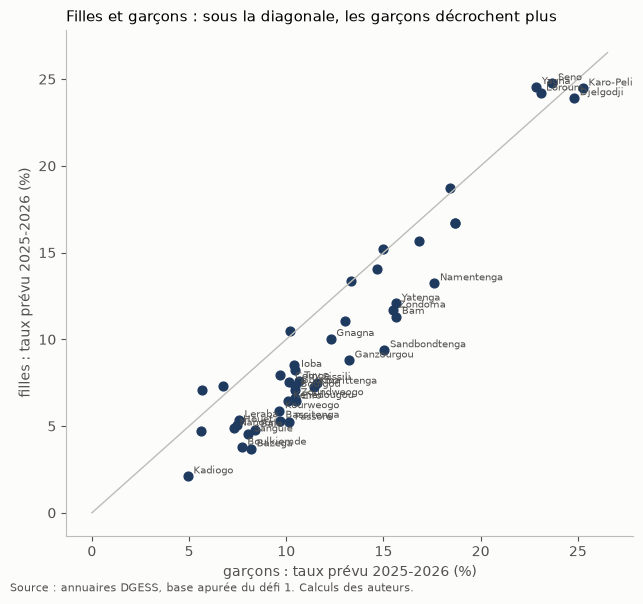

In [23]:
ts = tables["tableau_de_bord_sexe"]
large = ts.pivot_table(index="province_nom", columns="sexe", values="taux_abandon_prevu")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(large["G"], large["F"], color="#1f3a5f", s=40)
borne = [0, max(large.max()) * 1.05]
ax.plot(borne, borne, color="#bdbcb6", lw=1)
for nom, r in large.iterrows():
    if abs(r["F"] - r["G"]) > 2 or r.max() > 20:
        ax.annotate(nom, (r["G"], r["F"]), xytext=(4, 2), textcoords="offset points", fontsize=7.5, color="#52514e")
ax.set_xlabel("garçons : taux prévu 2025-2026 (%)"); ax.set_ylabel("filles : taux prévu 2025-2026 (%)")
ax.set_title("Filles et garçons : sous la diagonale, les garçons décrochent plus", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 6. Brique 3 : l'alerte de rupture

Régression logistique pénalisée sur des signaux connus à la date t. Mesure : AUC (probabilité qu'une province en rupture ait un score plus élevé qu'une autre) et nombre de ruptures retrouvées dans le quart des provinces au score le plus élevé.

In [24]:
tables["evaluation_alerte_rupture"]

,annee_cible,role,provinces,ruptures,auc,ruptures_dans_le_quart_le_plus_a_risque
0,2021-2022,sélection,43,5,0.874,4
1,2022-2023,sélection,40,8,0.852,7
2,2023-2024,sélection,34,2,0.906,2
3,2024-2025,test final,42,2,0.962,2


In [25]:
tables["coefficients_alerte_rupture"]

,variable,libelle,coefficient_standardise
6,hors_ecole_16_18_province,jeunes de 16-18 ans hors de l'école,1.326
0,evolution_eleves_primaire,évolution des effectifs,-1.044
2,rupture_annee_precedente,rupture l'année précédente,-0.923
4,abandon_primaire_precedent,abandon de l'année,0.905
3,ruptures_passees,ruptures passées,0.422
5,abandons_primaire_orpaillage_pour_1000_region,abandons pour l'orpaillage (région),-0.406
1,baisse_effectifs,baisse des effectifs,-0.008


In [26]:
tables["alerte_rupture"].head(15)

,province_pcode,province_nom,region_nom,annee_prevue,score_rupture,risque_de_rupture
0,BF5902,Karo-Peli,Soum,2025-2026,0.995,élevé
1,BF6403,Yagha,Liptako,2025-2026,0.994,élevé
2,BF5901,Djelgodji,Soum,2025-2026,0.983,élevé
3,BF5401,Loroum,Yaadga,2025-2026,0.966,élevé
4,BF5802,Komandjari,Sirba,2025-2026,0.923,élevé
5,BF6402,Seno,Liptako,2025-2026,0.904,élevé
6,BF6001,Dyamongou,Tapoa,2025-2026,0.903,élevé
7,BF6401,Oudalan,Liptako,2025-2026,0.871,élevé
8,BF5801,Gnagna,Sirba,2025-2026,0.811,élevé
9,BF6002,Gobnangou,Tapoa,2025-2026,0.783,élevé


## Ce qu'il faut retenir

- **Le décrochage est structurel et persistant.** Le meilleur prévisionniste du taux d'abandon de l'an prochain est le niveau habituel de la province ; les modèles appris, même optimisés, ne font pas mieux durablement en validation dans le temps. On retient donc le plus simple, avec un intervalle à 80 % asymétrique, toujours entre 0 et 100 %, dont la couverture est vérifiée sur le test final.
- **Peu de variables expliquent l'essentiel des écarts entre provinces** : poids du CP1 (élèves perdus au fil du cycle), jeunes ni à l'école ni en emploi, déficit de places assises ; par sexe, retard scolaire, achèvement du post-primaire, élèves par maître, parité. Ce sont des leviers de long terme.
- **La rupture est conjoncturelle et se prévoit** : l'alerte retrouve la plupart des ruptures dans le quart des provinces les plus à risque (AUC de 0,85 à 0,96).
- **Les garçons décrochent plus que les filles** au primaire dans la plupart des provinces.

Les tables `tableau_de_bord_ensemble.csv` et `tableau_de_bord_sexe.csv` alimentent la carte et les fiches de l'étape 05.